# 02 · El modelo: goles de Poisson con ataque, defensa y ventaja local

**Objetivo.** Predecir, antes de cada partido, la probabilidad de que gane el local, empate o gane el visitante, usando **solo los resultados pasados**, y medir cuánto del hueco entre las frecuencias históricas (1,065) y Pinnacle (0,953) conseguimos cerrar.

**Plan del cuaderno**
1. La idea del modelo, con un partido de ejemplo.
2. Cómo evaluarlo sin "mirar el futuro" (validación temporal).
3. Dos refinamientos (que los partidos antiguos pesen menos y que los equipos con pocos datos no se desmadren) y cómo elegirlos.
4. Una corrección para los marcadores bajos (0-0, 1-1).
5. El **examen final** sobre partidos que no se han usado para elegir nada.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import futbol as fb
import modelo as m

fb.estilo()
pd.set_option("display.width", 140)
%matplotlib inline

df = fb.cargar_laliga()
idx = m.indices_equipos(df)            # {'Alaves': 0, 'Almeria': 1, ...}
nombres = {i: e for e, i in idx.items()}
n_eq = len(idx)
print(f"{fb.miles(len(df))} partidos, {n_eq} equipos")

8.058 partidos, 41 equipos


## 1. La idea del modelo

En el cuaderno anterior vimos que los goles de un equipo en un partido se parecen a una **distribución de Poisson**, cuya única cifra es la media: los *goles esperados*. La pregunta es qué media usar en cada partido. El modelo propone que depende de tres cosas:

$$\text{goles esperados del local} = \exp\big(\text{base} + \text{ventaja local} + \text{ataque}_{\text{local}} - \text{defensa}_{\text{visitante}}\big)$$
$$\text{goles esperados del visitante} = \exp\big(\text{base} + \text{ataque}_{\text{visitante}} - \text{defensa}_{\text{local}}\big)$$

* **ataque** de un equipo: cuanto más alto, más goles marca. Una defensa débil rival también ayuda.
* **defensa** de un equipo: cuanto más alta, **menos** goles concede.
* **ventaja local**: un único número, igual para todos los equipos.
* Se usa la exponencial `exp(...)` por dos razones: asegura que los goles esperados sean siempre positivos y hace que los efectos **se multipliquen**. Si el ataque de un equipo vale 0,3 significa que marca `exp(0,3) ≈ 1,35` veces los goles de un equipo medio.

Los parámetros (la base, la ventaja y el ataque y la defensa de cada uno de los 41 equipos) se **ajustan a los datos**: se buscan los valores que hacen más probables los resultados que realmente ocurrieron (*máxima verosimilitud*). El ajuste está en `src/modelo.py` y tarda unas centésimas de segundo.

### Un ajuste de ejemplo

Para ver los parámetros ajustamos el modelo con las últimas cinco temporadas (a partir de agosto de 2021).

In [2]:
reciente = df[df["fecha"] >= "2021-08-01"]
li = reciente["local"].map(idx).to_numpy()
vi = reciente["visitante"].map(idx).to_numpy()
gl = reciente["goles_local"].to_numpy(float)
gv = reciente["goles_visitante"].to_numpy(float)

theta = m.ajustar(li, vi, gl, gv, np.ones(len(reciente)), n_eq, ridge=2.0)
base, ventaja = theta[0], theta[1]
ataque = pd.Series(theta[2:2 + n_eq], index=[nombres[i] for i in range(n_eq)])
defensa = pd.Series(theta[2 + n_eq:], index=[nombres[i] for i in range(n_eq)])

print(f"Base: {base:.3f}  ->  un equipo medio, fuera de casa, marca exp({base:.3f}) = {np.exp(base):.2f} goles")
print(f"Ventaja local: {ventaja:.3f}  ->  jugar en casa multiplica los goles por exp({ventaja:.3f}) = {np.exp(ventaja):.2f}")

Base: 0.090  ->  un equipo medio, fuera de casa, marca exp(0.090) = 1.09 goles
Ventaja local: 0.280  ->  jugar en casa multiplica los goles por exp(0.280) = 1.32


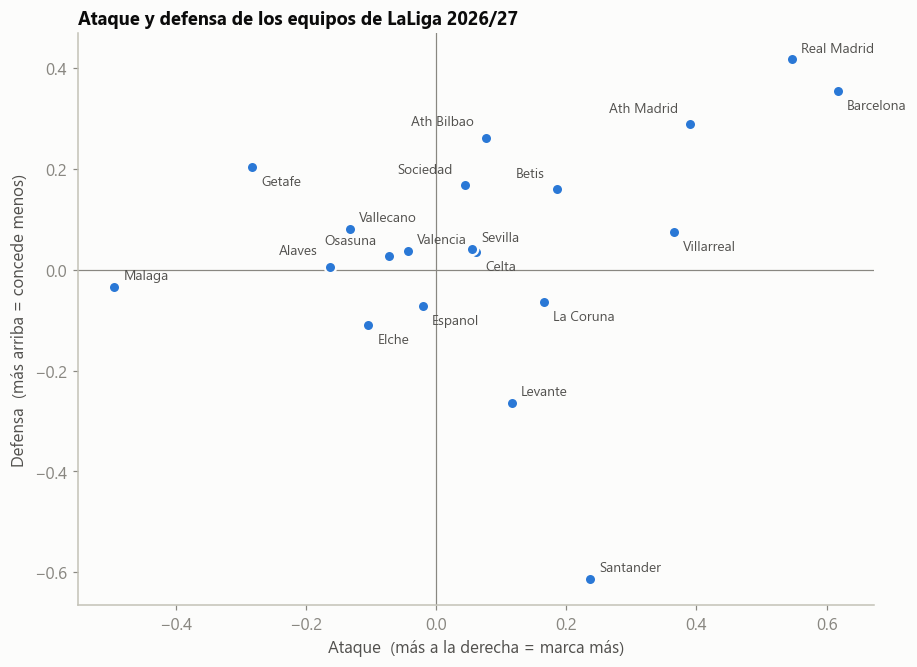

In [3]:
actuales = sorted(set(df[df["temporada"] == df["temporada"].iloc[-1]]["local"]))   # equipos de la temporada en curso

fig, ax = plt.subplots(figsize=(8.5, 6.2))
ax.axhline(0, color=fb.TINTA_SUAVE, lw=0.8); ax.axvline(0, color=fb.TINTA_SUAVE, lw=0.8)
ax.scatter(ataque[actuales], defensa[actuales], s=55, color=fb.COLOR_LOCAL, edgecolor=fb.SUPERFICIE, linewidth=1.5, zorder=3)
desplazamientos = [(6, 5), (6, -12), (-8, 8)]          # se alternan para que las etiquetas cercanas no se pisen
for k, e in enumerate(sorted(actuales, key=lambda t: ataque[t])):
    dx, dy = desplazamientos[k % 3]
    ax.annotate(e, (ataque[e], defensa[e]), xytext=(dx, dy), textcoords="offset points", fontsize=9,
                color=fb.TINTA_SECUNDARIA, ha="left" if dx > 0 else "right")
ax.grid(False)
ax.set_xlabel("Ataque  (más a la derecha = marca más)")
ax.set_ylabel("Defensa  (más arriba = concede menos)")
ax.set_title("Ataque y defensa de los equipos de LaLiga 2026/27")
plt.tight_layout()
plt.show()

### De los goles esperados a las probabilidades 1-X-2

Con los goles esperados de cada equipo (por ejemplo, 2,2 del local y 0,9 del visitante) se construye una tabla con la probabilidad de **cada marcador**: la de que el local marque *x* goles por la de que el visitante marque *y*. Sumando las casillas donde x > y se obtiene la probabilidad de que gane el local, donde x = y la del empate y donde x < y la del visitante.

Ejemplo con un partido hipotético: **Real Madrid - Barcelona** en el Bernabéu, con los parámetros que acabamos de ajustar.

Goles esperados:  Real Madrid 1.75   Barcelona 1.34


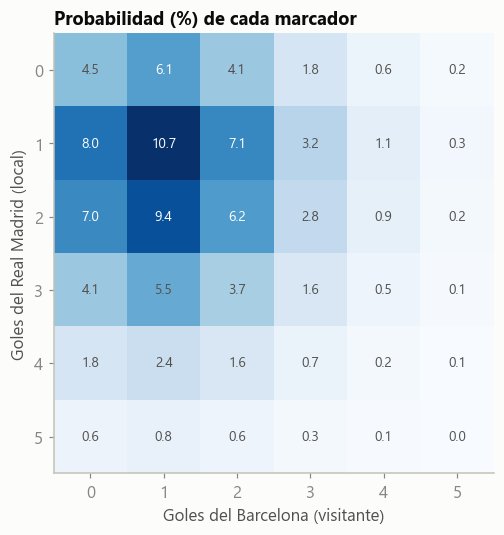

Gana el Real Madrid: 47.4 %   Empate: 23.3 %   Gana el Barcelona: 29.3 %


In [4]:
i_rm, i_fcb = idx["Real Madrid"], idx["Barcelona"]
lam, mu = m.goles_esperados(theta, n_eq, np.array([i_rm]), np.array([i_fcb]))
lam, mu = float(lam[0]), float(mu[0])
print(f"Goles esperados:  Real Madrid {lam:.2f}   Barcelona {mu:.2f}")

tabla = m.matriz_marcadores(lam, mu)[:6, :6] * 100
fig, ax = plt.subplots(figsize=(5.8, 5))
ax.imshow(tabla, cmap="Blues", origin="upper")
for x in range(6):
    for y in range(6):
        ax.text(y, x, f"{tabla[x, y]:.1f}", ha="center", va="center", fontsize=9,
                color="white" if tabla[x, y] > tabla.max() * 0.55 else fb.TINTA_SECUNDARIA)
ax.set_xlabel("Goles del Barcelona (visitante)")
ax.set_ylabel("Goles del Real Madrid (local)")
ax.set_title("Probabilidad (%) de cada marcador")
ax.grid(False)
plt.tight_layout()
plt.show()

p = m.probs_1x2(np.array([lam]), np.array([mu]))[0]
print(f"Gana el Real Madrid: {p[0]*100:.1f} %   Empate: {p[1]*100:.1f} %   Gana el Barcelona: {p[2]*100:.1f} %")

## 2. Cómo evaluar el modelo sin hacer trampa

Si ajustáramos el modelo con todos los partidos y luego lo probáramos sobre esos mismos partidos, obtendríamos un resultado inflado: el modelo **ya conocería las respuestas** (incluso conocería lo que pasó después de cada partido). Para estimar lo bien que predeciría un partido futuro de verdad hay que simular lo que habría pasado en la vida real:

> Cada semana, **ajustar el modelo solo con los partidos ya jugados** y predecir los partidos de esa semana. Luego avanzar a la semana siguiente.

Esto se llama **validación temporal** (*walk-forward*). La función `walk_forward()` lo hace: divide el tiempo en bloques de 7 días y antes de cada bloque reajusta el modelo con todo el pasado. Por ejemplo, para predecir los partidos del bloque que empieza el 1 de abril de 2019 solo se usan los partidos anteriores a esa fecha.

### Dos periodos distintos para dos cosas

* **2012/13 a 2018/19 (periodo de ajuste fino).** Aquí probaremos configuraciones del modelo y elegiremos la mejor.
* **2019/20 en adelante (examen final).** No lo tocaremos hasta el final. Así la nota que saquemos es honesta: la configuración no se ha elegido mirando estos partidos.

Ambos empiezan en 2012/13 porque es cuando hay cuotas de Pinnacle para comparar.

### Los puntos de comparación del periodo de ajuste

In [5]:
cols_ps = ["pinnacle_cierre_local", "pinnacle_cierre_empate", "pinnacle_cierre_visitante"]
cols_b365 = ["b365_local", "b365_empate", "b365_visitante"]
cols_prob = ["p_local", "p_empate", "p_visitante"]

def con_referencias(res):
    # Añade a las predicciones las probabilidades de las casas y se queda con los partidos que tienen cuotas de Pinnacle
    cuotas = df.set_index(["fecha", "local", "visitante"])[cols_ps + cols_b365]
    r = res.set_index(["fecha", "local", "visitante"]).join(cuotas).dropna(subset=cols_ps)
    pps, _ = fb.probabilidades_implicitas(*(r[c] for c in cols_ps))
    pb3, _ = fb.probabilidades_implicitas(*(r[c] for c in cols_b365))
    r[["ps_local", "ps_empate", "ps_visitante"]] = pps
    r[["b3_local", "b3_empate", "b3_visitante"]] = pb3
    return r

def frecuencias_historicas(antes_de):
    previos = df[(df["fecha"] < antes_de) & df["temporada_completa"]]
    return previos["resultado"].value_counts(normalize=True).reindex(["H", "D", "A"]).to_numpy()

def tabla_referencias(r, antes_de):
    y = m.indice_resultado(r["resultado"])
    freq = frecuencias_historicas(antes_de)
    return pd.Series({
        "Equiprobable": m.log_loss(np.full((len(y), 3), 1 / 3), y),
        "Frecuencias históricas": m.log_loss(np.tile(freq, (len(y), 1)), y),
        "Bet365": m.log_loss(r[["b3_local", "b3_empate", "b3_visitante"]].to_numpy(), y),
        "Pinnacle (cierre)": m.log_loss(r[["ps_local", "ps_empate", "ps_visitante"]].to_numpy(), y),
    })

AJUSTE = ("2012-08-01", "2019-06-30")
res_base = m.walk_forward(df, *AJUSTE, semividas_anios=None, ridge=2.0, indice=idx)
r_base = con_referencias(res_base)
ref_ajuste = tabla_referencias(r_base, "2012-08-01")
print(f"{fb.miles(len(r_base))} partidos del periodo de ajuste con cuotas de Pinnacle\n")
print(ref_ajuste.round(4))

2.659 partidos del periodo de ajuste con cuotas de Pinnacle

Equiprobable              1.0986
Frecuencias históricas    1.0567
Bet365                    0.9433
Pinnacle (cierre)         0.9382
dtype: float64


### Primer modelo: el más sencillo

Todos los partidos pasados pesan igual y una regularización suave (`ridge = 2`, que explicaremos enseguida).

In [6]:
y_base = m.indice_resultado(r_base["resultado"])
perdida_base = m.log_loss(r_base[cols_prob].to_numpy(), y_base)
hueco = m.hueco_cerrado(perdida_base, ref_ajuste["Frecuencias históricas"], ref_ajuste["Pinnacle (cierre)"])
print(f"Pérdida logarítmica del primer modelo: {perdida_base:.4f}")
print(f"Hueco cerrado entre las frecuencias históricas y Pinnacle: {hueco*100:.0f} %")

Pérdida logarítmica del primer modelo: 0.9611
Hueco cerrado entre las frecuencias históricas y Pinnacle: 81 %


**Con solo tres ingredientes (ataque, defensa y ventaja local) el modelo ya cierra el 81 % del hueco** entre las frecuencias históricas (1,0567) y Pinnacle (0,9382): queda a 0,023 de las cuotas de cierre de la mejor casa. Es lógico: casi toda la información útil para predecir un partido es "quién es bueno y quién no", y eso se aprende bien de los resultados pasados.

## 3. Dos refinamientos y cómo elegirlos

**1. Los partidos antiguos pesan menos (decaimiento).** La plantilla y el nivel de un equipo cambian con los años; un resultado de hace 8 años dice poco sobre cómo juega hoy. Se multiplica cada partido por un peso que se **reduce a la mitad cada *semivida*** (por ejemplo, 2 años). Con semivida 2 años, un partido de hace 2 años pesa 0,5; de hace 4, 0,25; de hace 6, 0,125.

**2. Regularización (*ridge*).** Con pocos partidos (un equipo recién ascendido) el ataque y la defensa pueden salir extremos por pura casualidad. La regularización añade una penalización a los parámetros grandes: los **encoge hacia 0**, que es "equipo medio". Cuanto mayor es `ridge`, más se encogen.

Hay dos "diales" (la semivida y el `ridge`) que no se aprenden de los datos y hay que elegir: se llaman **hiperparámetros**. Los elegimos probando una **rejilla** de combinaciones en el periodo de ajuste fino y quedándonos con la de menor pérdida.

In [7]:
semividas = [None, 4.0, 2.0, 1.0, 0.5]       # años (None = sin decaimiento)
ridges = [0.5, 2.0, 8.0]

resultados = {}
for sv in semividas:
    for rg in ridges:
        res = m.walk_forward(df, *AJUSTE, semividas_anios=sv, ridge=rg, indice=idx)
        r = con_referencias(res)
        resultados[(sv, rg)] = m.log_loss(r[cols_prob].to_numpy(), m.indice_resultado(r["resultado"]))

rejilla = pd.Series(resultados).unstack()
rejilla.index = ["sin decaimiento" if s is None else f"{s:g} años" for s in rejilla.index]
rejilla.columns = [f"ridge = {c:g}" for c in rejilla.columns]
print("Pérdida logarítmica (menor es mejor) en el periodo de ajuste:\n")
print(rejilla.round(4))

mejor = min(resultados, key=resultados.get)
SEMIVIDA, RIDGE = mejor
print(f"\nMejor combinación: semivida = {SEMIVIDA} años, ridge = {RIDGE}  ->  {resultados[mejor]:.4f}")

Pérdida logarítmica (menor es mejor) en el periodo de ajuste:

          ridge = 0.5  ridge = 2  ridge = 8
nan años       0.9613     0.9611     0.9618
0.5 años       0.9594     0.9582     0.9633
1 años         0.9553     0.9550     0.9578
2 años         0.9559     0.9558     0.9574
4 años         0.9577     0.9576     0.9587

Mejor combinación: semivida = 1.0 años, ridge = 2.0  ->  0.9550


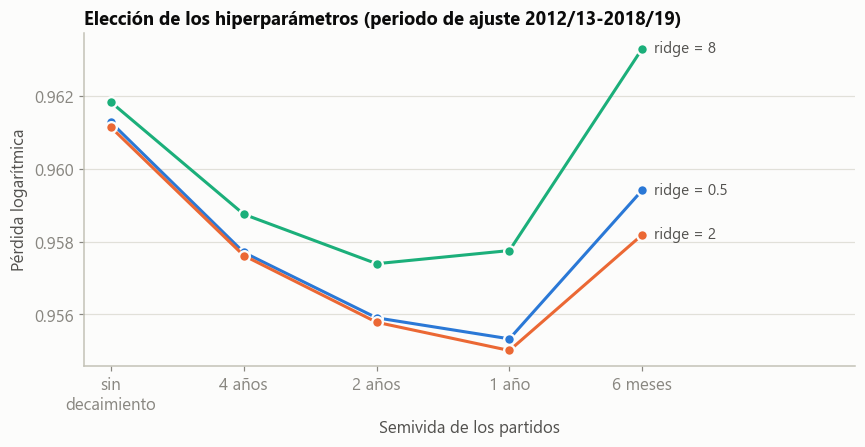

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
colores = [fb.COLOR_LOCAL, fb.COLOR_VISITANTE, "#1baf7a"]
for (rg, col) in zip(ridges, colores):
    ax.plot(range(len(semividas)), [resultados[(sv, rg)] for sv in semividas], "o-", color=col, markersize=7,
            markeredgecolor=fb.SUPERFICIE, markeredgewidth=1.5)
    ax.annotate(f"ridge = {rg:g}", (len(semividas) - 1, resultados[(semividas[-1], rg)]), xytext=(8, 0),
                textcoords="offset points", va="center", color=fb.TINTA_SECUNDARIA, fontsize=10)
ax.set_xticks(range(len(semividas)))
ax.set_xticklabels(["sin\ndecaimiento", "4 años", "2 años", "1 año", "6 meses"])
ax.set_xlim(-0.2, len(semividas) + 0.6)
ax.set_xlabel("Semivida de los partidos")
ax.set_ylabel("Pérdida logarítmica")
ax.set_title("Elección de los hiperparámetros (periodo de ajuste 2012/13-2018/19)")
plt.tight_layout()
plt.show()

**La curva tiene forma de U:** hay un óptimo interior.

* **Sin decaimiento** (todos los partidos pesan igual) es lo peor (0,9611): mezcla épocas en las que los equipos eran muy distintos.
* Con **semivida de 1 año** se llega al mínimo (0,9550). Que los partidos de hace un año pesen la mitad que los de ahora sugiere que la forma de un equipo cambia en una escala de pocas temporadas.
* Con **6 meses** empeora otra vez: quedan tan pocos partidos con peso que el modelo se vuelve ruidoso.
* El mejor `ridge` es 2: con 0,5 los equipos con pocos datos se desmandan un poco, y con 8 se encoge demasiado a todos hacia la media.

Las diferencias entre combinaciones vecinas son de milésimas, así que no hay que tomarse la "mejor" como mágica; lo robusto es la forma general: algo de decaimiento y una regularización moderada.

## 4. Corrección de Dixon-Coles para los marcadores bajos

El modelo supone que los goles del local y del visitante son **independientes**. En la realidad, algunos marcadores bajos no cuadran con esa independencia: el **0-0 y el 1-1 ocurren algo más** y el 1-0 y el 0-1 algo menos de lo que dice el producto de dos Poisson. Los investigadores Dixon y Coles propusieron en 1997 multiplicar la probabilidad de esos cuatro marcadores por un pequeño factor que depende de un parámetro $\rho$.

No toca los demás marcadores y se estima con los datos. Probamos si mejora (con los mejores hiperparámetros del apartado anterior).

In [9]:
res_tuned = m.walk_forward(df, *AJUSTE, semividas_anios=SEMIVIDA, ridge=RIDGE, indice=idx)
res_dc = m.walk_forward(df, *AJUSTE, semividas_anios=SEMIVIDA, ridge=RIDGE, dixon_coles=True, indice=idx)

filas = {}
for nombre, res in [("Primer modelo", res_base), ("+ decaimiento y ridge", res_tuned), ("+ Dixon-Coles", res_dc)]:
    r = con_referencias(res)
    y = m.indice_resultado(r["resultado"])
    p = r[cols_prob].to_numpy()
    perd = m.log_loss(p, y)
    filas[nombre] = {"pérdida": perd,
                     "hueco cerrado": m.hueco_cerrado(perd, ref_ajuste["Frecuencias históricas"], ref_ajuste["Pinnacle (cierre)"]),
                     "% empates previsto": p[:, 1].mean() * 100,
                     "% empates real": (y == 1).mean() * 100}
tabla = pd.DataFrame(filas).T
tabla["hueco cerrado"] = (tabla["hueco cerrado"] * 100).round(1).astype(str) + " %"
print(tabla.round(4))
print(f"\nValor medio de rho estimado: {res_dc['rho'].mean():.3f}")

                       pérdida hueco cerrado  % empates previsto  % empates real
Primer modelo           0.9611        80.7 %             23.7946          23.994
+ decaimiento y ridge   0.9550        85.8 %             23.4211          23.994
+ Dixon-Coles           0.9554        85.5 %             23.7132          23.994

Valor medio de rho estimado: -0.014


**La corrección de Dixon-Coles apenas importa aquí.** El parámetro $\rho$ sale prácticamente cero (en promedio −0,014) y la pérdida no mejora: 0,9554 frente a 0,9550 sin ella. Además, el modelo ya acierta el porcentaje de empates (prevé un 23,4 % y en realidad hubo un 24,0 %).

**Decisión:** el modelo final **no** lleva Dixon-Coles. La regla es elegir con el periodo de ajuste, no con el examen, así que no la cambiamos pase lo que pase después. Aun así, la mostramos en el examen para ser transparentes.

## 5. El examen final

Ahora usamos la configuración elegida (`semivida` y `ridge` del apartado 3) sobre los partidos **desde la temporada 2019/20 hasta hoy**, que no se han usado para decidir nada. Comparamos con los mismos puntos de referencia, siempre sobre **los mismos partidos** (los que tienen cuotas de Pinnacle).

In [10]:
EXAMEN = ("2019-08-01", "2026-12-31")
res_ex = {
    "Modelo: primer modelo": m.walk_forward(df, *EXAMEN, semividas_anios=None, ridge=2.0, indice=idx),
    "Modelo: + decaimiento y ridge": m.walk_forward(df, *EXAMEN, semividas_anios=SEMIVIDA, ridge=RIDGE, indice=idx),
    "Modelo: + Dixon-Coles": m.walk_forward(df, *EXAMEN, semividas_anios=SEMIVIDA, ridge=RIDGE, dixon_coles=True, indice=idx),
}
r_ex = {k: con_referencias(v) for k, v in res_ex.items()}
r0 = next(iter(r_ex.values()))
ref_ex = tabla_referencias(r0, "2019-08-01")

y_ex = m.indice_resultado(r0["resultado"])
perdidas = ref_ex.copy()
for k, r in r_ex.items():
    perdidas[k] = m.log_loss(r[cols_prob].to_numpy(), y_ex)

orden = ["Equiprobable", "Frecuencias históricas", "Modelo: primer modelo", "Modelo: + decaimiento y ridge",
         "Modelo: + Dixon-Coles", "Bet365", "Pinnacle (cierre)"]
perdidas = perdidas[orden]
hueco = m.hueco_cerrado(perdidas, ref_ex["Frecuencias históricas"], ref_ex["Pinnacle (cierre)"])
print(f"{fb.miles(len(r0))} partidos del examen con cuotas de Pinnacle (2019/20 en adelante)")
print("Modelo final elegido ANTES del examen, con el periodo de ajuste: decaimiento + ridge, sin Dixon-Coles\n")
print(pd.DataFrame({"pérdida": perdidas.round(4), "hueco cerrado": (hueco * 100).round(1).astype(str) + " %"}))

2.468 partidos del examen con cuotas de Pinnacle (2019/20 en adelante)
Modelo final elegido ANTES del examen, con el periodo de ajuste: decaimiento + ridge, sin Dixon-Coles

                               pérdida hueco cerrado
Equiprobable                    1.0986       -23.5 %
Frecuencias históricas          1.0738         0.0 %
Modelo: primer modelo           0.9931        76.3 %
Modelo: + decaimiento y ridge   0.9874        81.7 %
Modelo: + Dixon-Coles           0.9864        82.6 %
Bet365                          0.9710        97.2 %
Pinnacle (cierre)               0.9680       100.0 %


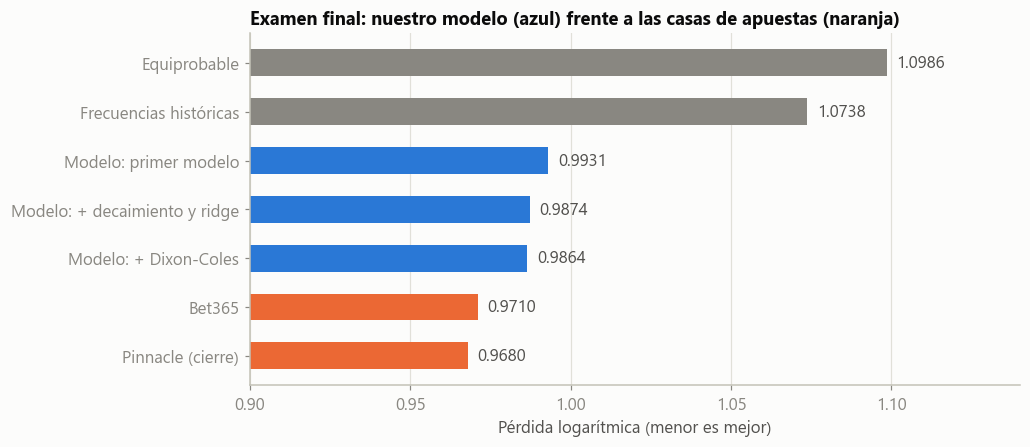

In [11]:
colores_barras = [fb.TINTA_SUAVE, fb.TINTA_SUAVE, fb.COLOR_LOCAL, fb.COLOR_LOCAL, fb.COLOR_LOCAL, fb.COLOR_VISITANTE, fb.COLOR_VISITANTE]
fig, ax = plt.subplots(figsize=(9.5, 4.2))
barras = ax.barh(perdidas.index[::-1], perdidas.values[::-1], color=colores_barras[::-1], height=0.55)
for rect, v in zip(barras, perdidas.values[::-1]):
    ax.text(v + 0.003, rect.get_y() + rect.get_height() / 2, f"{v:.4f}", va="center", color=fb.TINTA_SECUNDARIA)
ax.set_xlim(0.9, 1.14)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("Pérdida logarítmica (menor es mejor)")
ax.set_title("Examen final: nuestro modelo (azul) frente a las casas de apuestas (naranja)")
plt.tight_layout()
plt.show()

### ¿Es estable? Resultados por temporada

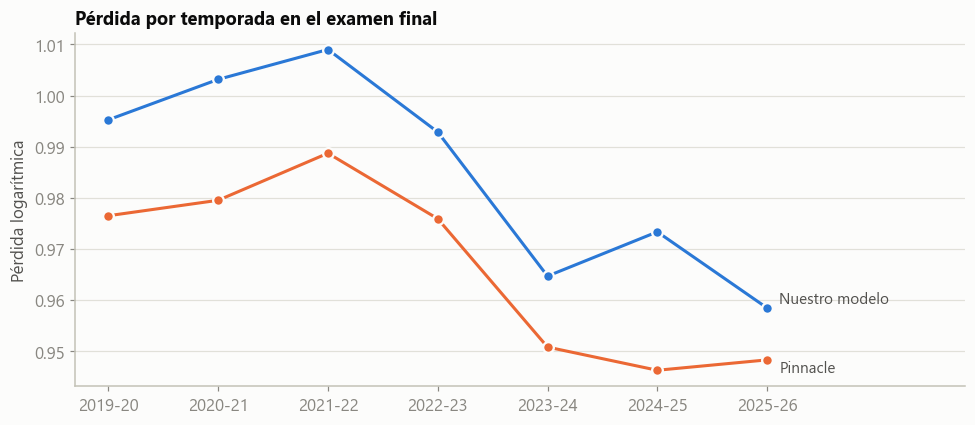

         modelo  pinnacle  partidos
2019-20  0.9953    0.9765       380
2020-21  1.0032    0.9795       380
2021-22  1.0090    0.9887       380
2022-23  0.9929    0.9759       380
2023-24  0.9647    0.9509       380
2024-25  0.9734    0.9463       380
2025-26  0.9585    0.9484       188


In [12]:
MODELO_FINAL = "Modelo: + decaimiento y ridge"      # elegido con el periodo de ajuste: Dixon-Coles no mejoraba
r_final = r_ex[MODELO_FINAL]
y_f = m.indice_resultado(r_final["resultado"])
por_temp = pd.DataFrame({
    "modelo": [m.log_loss(g[cols_prob].to_numpy(), m.indice_resultado(g["resultado"])) for _, g in r_final.groupby("temporada")],
    "pinnacle": [m.log_loss(g[["ps_local", "ps_empate", "ps_visitante"]].to_numpy(), m.indice_resultado(g["resultado"])) for _, g in r_final.groupby("temporada")],
    "partidos": r_final.groupby("temporada").size().to_numpy(),
}, index=sorted(r_final["temporada"].unique()))

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(por_temp))
ax.plot(x, por_temp["modelo"], "o-", color=fb.COLOR_LOCAL, markersize=7, markeredgecolor=fb.SUPERFICIE, markeredgewidth=1.5)
ax.plot(x, por_temp["pinnacle"], "o-", color=fb.COLOR_VISITANTE, markersize=7, markeredgecolor=fb.SUPERFICIE, markeredgewidth=1.5)
ax.annotate("Nuestro modelo", (x[-1], por_temp["modelo"].iloc[-1]), xytext=(8, 3), textcoords="offset points", color=fb.TINTA_SECUNDARIA, fontsize=10)
ax.annotate("Pinnacle", (x[-1], por_temp["pinnacle"].iloc[-1]), xytext=(8, -8), textcoords="offset points", color=fb.TINTA_SECUNDARIA, fontsize=10)
ax.set_xticks(x); ax.set_xticklabels(por_temp.index, rotation=0)
ax.set_xlim(-0.3, len(x) + 0.8)
ax.set_ylabel("Pérdida logarítmica")
ax.set_title("Pérdida por temporada en el examen final")
plt.tight_layout()
plt.show()
print(por_temp.round(4))

**Lectura del examen** (pérdida logarítmica, menor es mejor):

* El **modelo final (0,9874)** cierra el **81,7 %** del hueco entre las frecuencias históricas (1,0738) y Pinnacle (0,9680).
* Queda **0,019 por detrás de Pinnacle** y 0,016 por detrás de Bet365. Para hacerse una idea: la probabilidad media (geométrica) que nuestro modelo daba al resultado que ocurrió es del 37,3 %; la de Pinnacle, del 38,0 %.
* Dixon-Coles habría dado 0,9864, una milésima mejor: irrelevante, y no cambia nuestra decisión previa.
* Por temporadas, el modelo queda por detrás de Pinnacle **todos los años** (entre 0,010 y 0,027), y ambos suben y bajan a la vez: las temporadas 2020/21 y 2021/22 fueron las más difíciles de predecir para todos.

Es el resultado esperable: el modelo solo conoce los goles pasados, mientras que Pinnacle también conoce las lesiones, las alineaciones y el dinero que mueven los apostadores profesionales.

### El futuro de verdad: la temporada en curso

Los partidos de 2026/27 aún no tienen cuotas de Pinnacle en los datos, pero sí de **Bet365** y de la **media del mercado al cierre**. Comparamos con ellas sobre los partidos ya jugados (son pocos, así que el resultado es muy ruidoso).

In [13]:
res_cur = res_ex[MODELO_FINAL]
res_cur = res_cur[res_cur["temporada"] == df["temporada"].iloc[-1]]
datos = df.set_index(["fecha", "local", "visitante"])
cols_avg = ["media_cierre_local", "media_cierre_empate", "media_cierre_visitante"]
c = res_cur.set_index(["fecha", "local", "visitante"]).join(datos[cols_b365 + cols_avg]).dropna(subset=cols_b365 + cols_avg)
yc = m.indice_resultado(c["resultado"])
pb, _ = fb.probabilidades_implicitas(*(c[k] for k in cols_b365))
pa, _ = fb.probabilidades_implicitas(*(c[k] for k in cols_avg))
print(f"{len(c)} partidos de {df['temporada'].iloc[-1]} ya jugados\n")
print(f"Nuestro modelo:            {m.log_loss(c[cols_prob].to_numpy(), yc):.4f}")
print(f"Bet365:                    {m.log_loss(pb, yc):.4f}")
print(f"Media del mercado (cierre): {m.log_loss(pa, yc):.4f}")
print(f"Equiprobable:              {m.log_loss(np.full((len(yc), 3), 1 / 3), yc):.4f}")

78 partidos de 2026-27 ya jugados

Nuestro modelo:            0.9466
Bet365:                    0.9298
Media del mercado (cierre): 0.9153
Equiprobable:              1.0986


**Con solo 78 partidos hay que tener cuidado.** El modelo (0,9466) queda por detrás de Bet365 (0,9298) y de la media del mercado (0,9153), una diferencia parecida a la del examen. Pero con tan pocos partidos el margen de error de cada cifra es de varias centésimas (unas 0,05), mayor que las diferencias entre predictores, así que **no se puede concluir nada**. Lo útil es que este conjunto irá creciendo cada jornada y es "futuro de verdad": el modelo nunca lo ha visto.

## 6. Conclusiones

**El modelo.** Goles de Poisson con ataque y defensa por equipo y ventaja local, con **semivida de 1 año** y **ridge = 2** (elegidos en 2012/13-2018/19), sin la corrección de Dixon-Coles (no mejoraba).

**El resultado.** En el examen final (2019/20 en adelante, 2.468 partidos) la pérdida logarítmica es **0,9874**, frente a 1,0738 de las frecuencias históricas y 0,9680 de Pinnacle: el modelo cierra el **82 % del hueco**. Es un resultado estable: queda por detrás de Pinnacle en las siete temporadas, siempre por entre 0,010 y 0,027.

**Lo que hemos aprendido del método**
* La **validación temporal** (reajustar cada semana solo con el pasado) evita el espejismo de predecir partidos cuyo resultado el modelo ya conoce.
* **Elegir con un periodo y examinar con otro** hace honesta la nota final. Dixon-Coles es un buen ejemplo: no mejoró en el periodo de ajuste, así que no se usó, aunque en el examen habría ganado una milésima. La decisión no se cambia mirando el examen.
* Los hiperparámetros tienen un óptimo interior (la curva en U de la rejilla): muy poca memoria pierde información y demasiada mezcla épocas distintas.

**Limitaciones (lo que el modelo no sabe)**
* No conoce **lesiones, alineaciones, sanciones ni el calendario** (descansos, partidos de Champions), información que el mercado sí incorpora.
* Los equipos **recién ascendidos** empiezan con un nivel "medio" (en realidad suelen ser más débiles).
* La ventaja local es **igual para todos** los equipos, y el ataque y la defensa de cada equipo se ajustan con goles, que son pocos y ruidosos.

**Siguiente paso.** El modelo usa solo goles, pero cada partido trae también **tiros y tiros a puerta**, que son una señal más estable de la calidad de un equipo que los propios goles (que dependen mucho de la suerte). En el cuaderno 03 probaremos a incorporarlos, y después construiremos la app.